In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

print("TensorFlow:", tf.__version__)

# Dataset path
dataset_path = Path("../dataset/chest_xray")

# Settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Dataset:", dataset_path.resolve())

TensorFlow: 2.21.0
Dataset: D:\Tanu H\TanushrisSPace\Projects\DL MINI PROJECT\dataset\chest_xray


In [2]:
# Load datasets

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "train",
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "val",
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "test",
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nClasses:", train_ds.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.

Classes: ['NORMAL', 'PNEUMONIA']


In [3]:
# Data augmentation

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10)
], name="data_augmentation")

print("✅ Data augmentation ready!")

✅ Data augmentation ready!


In [4]:
# Load pretrained ResNet50

base_model = tf.keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers
base_model.trainable = False

print("Total ResNet50 layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 236s 2us/step
Total ResNet50 layers: 175
Trainable: False


In [5]:
# Build ResNet50 classification model

inputs = tf.keras.Input(shape=(224, 224, 3))

# Data augmentation
x = data_augmentation(inputs)

# ResNet50 preprocessing
x = tf.keras.applications.resnet50.preprocess_input(x)

# Pretrained ResNet50 feature extractor
x = base_model(x, training=False)

# Convert feature maps into a single feature vector
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Regularization
x = tf.keras.layers.Dropout(0.4)(x)

# Binary classification
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

resnet_model = tf.keras.Model(inputs, outputs)

resnet_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │      2,049 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [6]:
# Compile ResNet50

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("✅ ResNet50 is ready for training!")

✅ ResNet50 is ready for training!


In [7]:
# Callbacks

resnet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "../results/resnet50_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

# Train ResNet50
resnet_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=resnet_callbacks
)

Epoch 1/10


d:\Tanu H\TanushrisSPace\Projects\DL MINI PROJECT\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


163/163 ━━━━━━━━━━━━━━━━━━━━ 436s 3s/step - accuracy: 0.7515 - loss: 0.5213 - precision: 0.8125 - recall: 0.8653 - val_accuracy: 0.5000 - val_loss: 0.9191 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 706s 4s/step - accuracy: 0.8491 - loss: 0.3462 - precision: 0.8762 - recall: 0.9280 - val_accuracy: 0.5625 - val_loss: 0.8144 - val_precision: 0.5333 - val_recall: 1.0000
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 325s 2s/step - accuracy: 0.8832 - loss: 0.2782 - precision: 0.9042 - recall: 0.9427 - val_accuracy: 0.6250 - val_loss: 0.7762 - val_precision: 0.5714 - val_recall: 1.0000
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 322s 2s/step - accuracy: 0.8992 - loss: 0.2411 - precision: 0.9210 - recall: 0.9453 - val_accuracy: 0.6250 - val_loss: 0.7836 - val_precision: 0.5714 - val_recall: 1.0000
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 321s 2s/step - accuracy: 0.9137 - loss: 0.2150 - precision: 0.9319 - recall: 0.9535 - val_accuracy: 0.6250 - val_loss: 0.7649 -

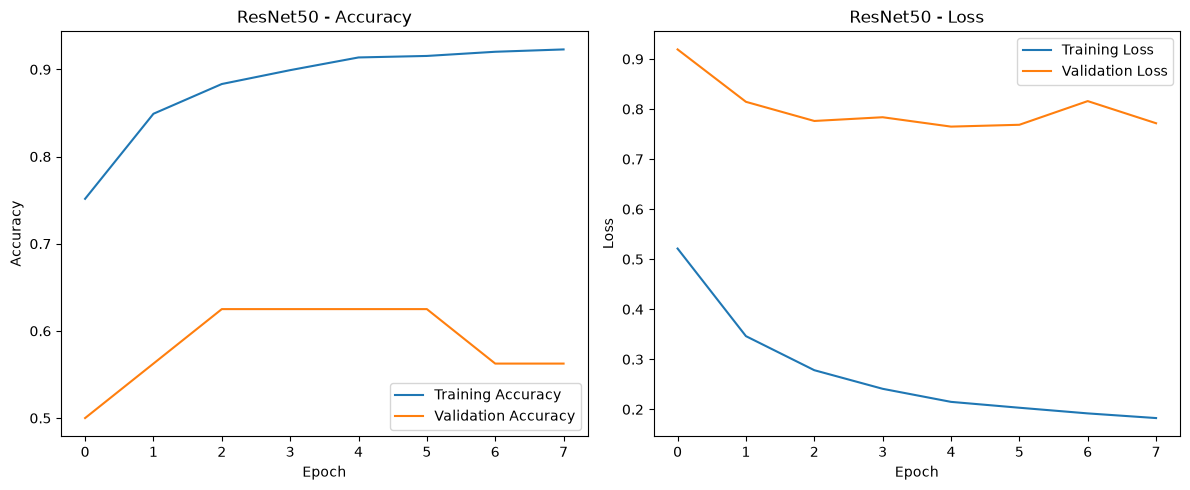

In [8]:
# Plot ResNet50 training and validation curves

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(resnet_history.history["accuracy"], label="Training Accuracy")
plt.plot(resnet_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ResNet50 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(resnet_history.history["loss"], label="Training Loss")
plt.plot(resnet_history.history["val_loss"], label="Validation Loss")
plt.title("ResNet50 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
# Evaluate ResNet50 on the test set

resnet_test_results = resnet_model.evaluate(test_ds, verbose=1)

print("\nResNet50 Test Results")
print("=" * 40)

for metric_name, value in zip(
    resnet_model.metrics_names,
    resnet_test_results
):
    print(f"{metric_name}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.7179 - loss: 0.6674 - precision: 0.6918 - recall: 0.9897

ResNet50 Test Results
loss: 0.6674
compile_metrics: 0.7179


In [10]:
# Generate predictions for the test dataset

resnet_y_true = []
resnet_y_prob = []

for images, labels in test_ds:
    probabilities = resnet_model.predict(images, verbose=0)

    resnet_y_prob.extend(probabilities.ravel())
    resnet_y_true.extend(labels.numpy().ravel())

resnet_y_true = np.array(resnet_y_true)
resnet_y_prob = np.array(resnet_y_prob)

# Convert probabilities to class predictions
resnet_y_pred = (resnet_y_prob >= 0.5).astype(int)

print("Total test samples:", len(resnet_y_true))
print("ResNet50 predictions generated successfully.")

Total test samples: 624
ResNet50 predictions generated successfully.


In [11]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Confusion matrix
resnet_cm = confusion_matrix(
    resnet_y_true,
    resnet_y_pred
)

print("ResNet50 Confusion Matrix:")
print(resnet_cm)

# Classification report
print("\nResNet50 Classification Report:")
print(
    classification_report(
        resnet_y_true,
        resnet_y_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)

# F1-score
resnet_f1 = f1_score(
    resnet_y_true,
    resnet_y_pred
)

# ROC-AUC
resnet_roc_auc = roc_auc_score(
    resnet_y_true,
    resnet_y_prob
)

print(f"\nF1-Score: {resnet_f1:.4f}")
print(f"ROC-AUC:  {resnet_roc_auc:.4f}")

ResNet50 Confusion Matrix:
[[ 62 172]
 [  4 386]]

ResNet50 Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9394    0.2650    0.4133       234
   PNEUMONIA     0.6918    0.9897    0.8143       390

    accuracy                         0.7179       624
   macro avg     0.8156    0.6274    0.6138       624
weighted avg     0.7846    0.7179    0.6640       624


F1-Score: 0.8143
ROC-AUC:  0.9258


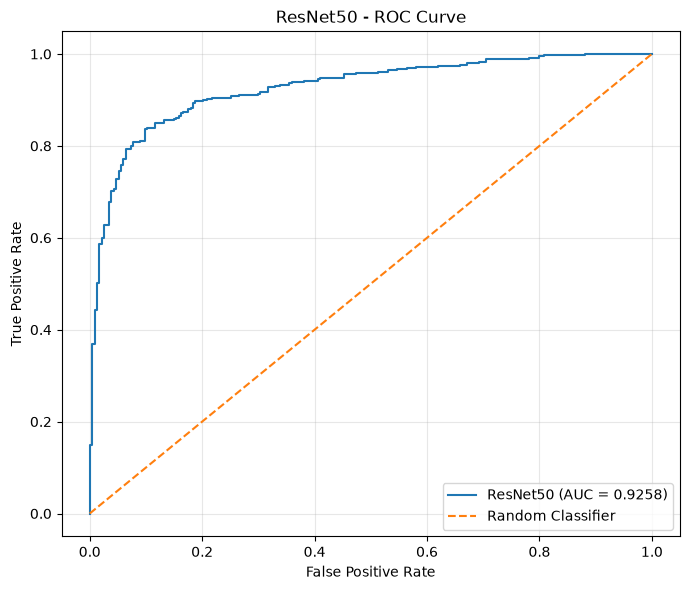

In [12]:
from sklearn.metrics import roc_curve

resnet_fpr, resnet_tpr, resnet_thresholds = roc_curve(
    resnet_y_true,
    resnet_y_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    resnet_fpr,
    resnet_tpr,
    label=f"ResNet50 (AUC = {resnet_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ResNet50 - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# Save ResNet50 evaluation results

resnet_results = {
    "Model": "ResNet50",
    "Test Accuracy": 0.7179,
    "Precision": 0.6918,
    "Recall": 0.9897,
    "F1-Score": 0.8143,
    "ROC-AUC": 0.9258,
    "Test Loss": 0.6674
}

resnet_results_df = pd.DataFrame([resnet_results])

resnet_results_df.to_csv(
    "../results/resnet50_results.csv",
    index=False
)

print("✅ ResNet50 results saved!")
print(resnet_results_df)

✅ ResNet50 results saved!
      Model  Test Accuracy  Precision  Recall  F1-Score  ROC-AUC  Test Loss
0  ResNet50         0.7179     0.6918  0.9897    0.8143   0.9258     0.6674


In [14]:
# Create combined model comparison table

comparison_df = pd.DataFrame([
    {
        "Model": "Custom CNN",
        "Test Accuracy": 0.8894,
        "Precision": 0.8759,
        "Recall": 0.9590,
        "F1-Score": 0.9155,
        "ROC-AUC": 0.9544,
        "Test Loss": 0.3016
    },
    {
        "Model": "ResNet50",
        "Test Accuracy": 0.7179,
        "Precision": 0.6918,
        "Recall": 0.9897,
        "F1-Score": 0.8143,
        "ROC-AUC": 0.9258,
        "Test Loss": 0.6674
    }
])

comparison_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("✅ Model comparison saved!")
display(comparison_df)

✅ Model comparison saved!


,Model,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC,Test Loss
0,Custom CNN,0.8894,0.8759,0.9590,0.9155,0.9544,0.3016
1,ResNet50,0.7179,0.6918,0.9897,0.8143,0.9258,0.6674
